# Chapitre 6 - Cours 4 : Agents et mémoire

Le RAG donne au modèle un outil : un retriever. Les **agents** généralisent l'idée : le modèle
dispose d'un **inventaire d'outils**, **planifie** une suite d'actions, observe les résultats
et se corrige. Ce notebook couvre les sections *Agents* (*Agent Overview*, *Tools*,
*Planning*, *Agent Failure Modes and Evaluation*) et *Memory*. L'auteure prévient que cette
partie du livre est plus expérimentale : le domaine évolue vite. Nous construisons tout à la
main avec Qwen2.5-0.5B-Instruct, qui gère nativement l'appel de fonctions en JSON.

Plan :

1. qu'est-ce qu'un agent ? environnement, actions, erreurs composées ;
2. les outils : inventaire, catégories, lecture et écriture ;
3. l'appel de fonctions en JSON avec Qwen ;
4. la planification : générer, valider, exécuter ;
5. la boucle ReAct ;
6. réflexion et correction d'erreurs ;
7. modes d'échec, évaluation et choix des outils ;
8. la mémoire : court terme, long terme, stratégies d'éviction.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import json
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 110)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
tok, _ = llm.load(llm.SMALL)
ntok = lambda t: len(tok(t)["input_ids"])  # noqa: E731

## 1. Qu'est-ce qu'un agent ? (section *Agent Overview*)

Suivant Russell et Norvig, un **agent** est tout ce qui **perçoit** son environnement et **agit**
sur lui. Il est donc caractérisé par son **environnement** (un jeu, Internet, un terminal, une
cuisine) et par l'ensemble des **actions** qu'il peut effectuer, étendu par ses **outils**. Les
deux sont liés : l'environnement détermine les outils possibles, et l'inventaire d'outils
restreint les environnements accessibles. Dans un agent à base de modèle de fondation, le
modèle est le **cerveau** : il reçoit la tâche et les retours de l'environnement, planifie les
actions et décide si la tâche est accomplie. Un RAG est un agent dont l'unique outil est un
retriever ; un RAG tabulaire en a deux (générer du SQL, l'exécuter).

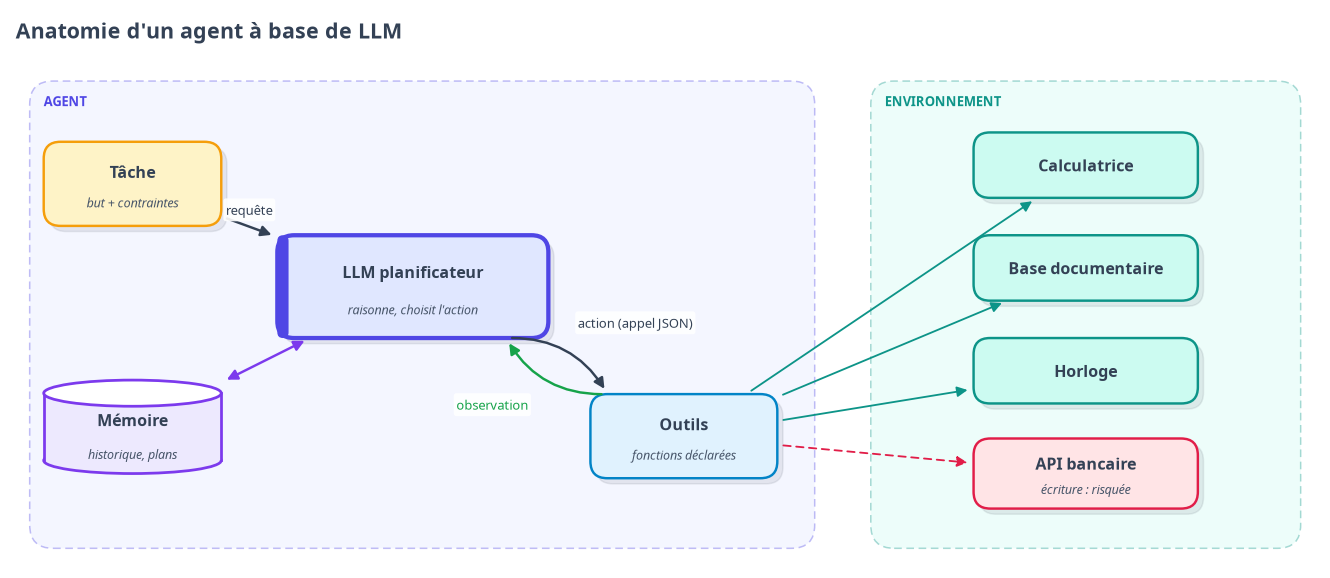

In [2]:
d = Diagram(14, 5.4, title="Anatomie d'un agent à base de LLM")
d.group(0.2, 0.2, 8.6, 5.2, "agent", color=INDIGO)
d.group(9.2, 0.2, 13.8, 5.2, "environnement", color=TEAL)
d.box("user", 1.3, 4.1, "Tâche", sub="but + contraintes", color=AMBER, w=1.9)
d.box("llm", 4.3, 3.0, "LLM planificateur", sub="raisonne, choisit l'action", color=INDIGO, kind="model", w=2.9, h=1.1)
d.box("mem", 1.3, 1.5, "Mémoire", sub="historique, plans", color=VIOLET, kind="db", w=1.9, h=1.0)
d.box("tools", 7.2, 1.4, "Outils", sub="fonctions déclarées", color=SKY, w=2.0)
d.box("calc", 11.5, 4.3, "Calculatrice", color=TEAL, w=2.4, h=0.7)
d.box("corpus", 11.5, 3.2, "Base documentaire", color=TEAL, w=2.4, h=0.7)
d.box("date", 11.5, 2.1, "Horloge", color=TEAL, w=2.4, h=0.7)
d.box("bank", 11.5, 1.0, "API bancaire", sub="écriture : risquée", color=ROSE, w=2.4, h=0.75)
d.arrow("user", "llm", "requête")
d.arrow("llm", "tools", "action (appel JSON)", rad=-0.3, label_offset=(0.75, 0.3))
d.arrow("mem", "llm", both=True, color=VIOLET)
for t_ in ["calc", "corpus", "date"]:
    d.arrow("tools", t_, color=TEAL, lw=1.2)
d.arrow("tools", "bank", color=ROSE, style="dashed", lw=1.2)
d.arrow("tools", "llm", "observation", rad=-0.3, color=GREEN, label_offset=(-0.6, -0.25))
d.show()

**Pourquoi les agents exigent des modèles plus forts.** Une tâche agentique enchaîne de
nombreuses étapes ; si chacune réussit avec une probabilité $p$ (indépendamment), la tâche
entière réussit avec probabilité $p^n$. Le livre donne l'exemple : 95 % par étape, c'est 60 %
sur 10 étapes et 0,6 % sur 100. Ajoutons que des **enjeux plus élevés** (actions réelles)
rendent chaque erreur plus coûteuse.

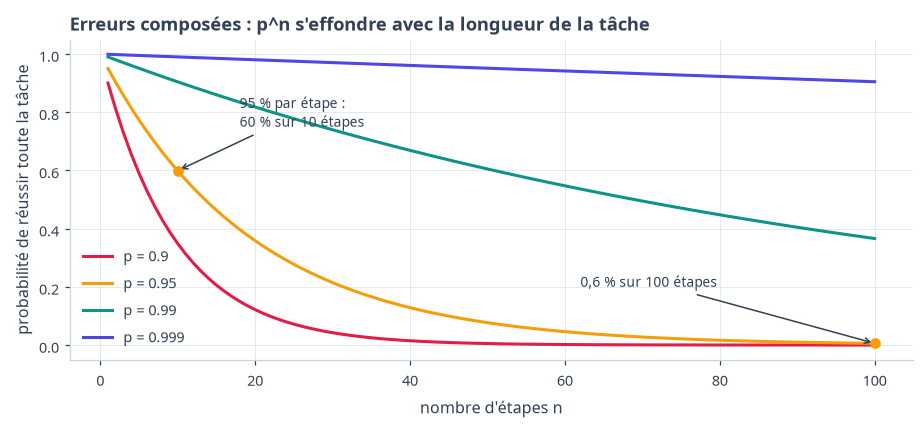

In [3]:
n = np.arange(1, 101)
fig, ax = plt.subplots(figsize=(8.5, 4))
for p_, col in [(0.90, ROSE), (0.95, AMBER), (0.99, TEAL), (0.999, INDIGO)]:
    ax.plot(n, c6.compound_success(p_, n), color=col, label=f"p = {p_}")
ax.scatter([10, 100], c6.compound_success(0.95, [10, 100]), color=AMBER, zorder=5)
ax.annotate("95 % par étape :\n60 % sur 10 étapes", (10, 0.599), xytext=(18, 0.75), arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.annotate("0,6 % sur 100 étapes", (100, 0.006), xytext=(62, 0.2), arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.set_xlabel("nombre d'étapes n"); ax.set_ylabel("probabilité de réussir toute la tâche")
ax.set_title("Erreurs composées : p^n s'effondre avec la longueur de la tâche"); ax.legend()
plt.tight_layout(); plt.show()

Inversement, pour viser 90 % de réussite sur $n$ étapes, il faut $p \geq 0{,}9^{1/n}$ : soit
98,9 % par étape pour 10 étapes et 99,9 % pour 100. D'où l'intérêt de la **réflexion** (repérer
et corriger les erreurs en cours de route) et de tâches courtes et bien découpées.

> **À retenir.** Un agent = un environnement + des actions (outils) + un modèle qui planifie.
> La fiabilité se dégrade exponentiellement avec le nombre d'étapes ($p^n$) : chaque étape doit
> être très fiable, ou vérifiée.

## 2. Les outils (section *Tools*)

Sans outil, un LLM ne sait faire qu'une chose : produire du texte. Le livre distingue trois
catégories d'outils :

| Catégorie | Rôle | Exemples |
|---|---|---|
| Augmentation des connaissances | construire le contexte | retriever, SQL, recherche Web, API internes |
| Extension des capacités | pallier les faiblesses du modèle | calculatrice, calendrier, convertisseur, interpréteur de code |
| Actions d'écriture | agir sur l'environnement | envoyer un courriel, modifier une base, virement |

Les outils de **lecture** permettent de percevoir, ceux d'**écriture** d'agir ; les seconds
exigent une confiance et des garde-fous bien plus grands (on ne laisse pas un stagiaire effacer
la base de production). Les outils peuvent aussi rendre un modèle texte « multimodal »
(générateur d'images, transcription). Notre inventaire ne contient que des outils **sûrs**, en
lecture seule ; la calculatrice n'utilise jamais `eval` mais un évaluateur d'arbre syntaxique
qui refuse tout ce qui n'est pas de l'arithmétique.

In [4]:
bm25 = c6.TermRetriever(TEXTS, IDS)
dense = c6.DenseRetriever(TEXTS, IDS)

def recherche(q):
    return [TXT[d_] for d_, _ in c6.rrf([bm25.search(q, 10), dense.search(q, 10)])][:2]

TOOLS = c6.make_tools(recherche)
pd.DataFrame([{"outil": t.name, "description": t.description[:80], "paramètres": ", ".join(t.parameters["properties"]) or "(aucun)",
               "écriture ?": t.write} for t in TOOLS.values()])

,outil,description,paramètres,écriture ?
0,calculatrice,"Évalue une expression arithmétique (+, -, *, /, **, sqrt, round). Exemple : '3 *",expression,False
1,recherche_corpus,"Cherche dans la base documentaire interne (produits Minou Chic, thermostat Therm",requete,False
2,date_du_jour,Renvoie la date d'aujourd'hui au format AAAA-MM-JJ.,(aucun),False
3,jours_entre,Nombre de jours entre deux dates au format AAAA-MM-JJ.,"date_debut, date_fin",False


In [5]:
print(json.dumps(TOOLS["jours_entre"].schema(), ensure_ascii=False, indent=1))
for expr in ["3 * 18", "round(199999 / 292, 2)", "__import__('os').system('ls')"]:
    try:
        print(f"calculatrice({expr!r}) -> {TOOLS['calculatrice'].fn(expr)}")
    except Exception as e:
        print(f"calculatrice({expr!r}) -> refusé : {e}")

{
 "type": "function",
 "function": {
  "name": "jours_entre",
  "description": "Nombre de jours entre deux dates au format AAAA-MM-JJ.",
  "parameters": {
   "type": "object",
   "properties": {
    "date_debut": {
     "type": "string"
    },
    "date_fin": {
     "type": "string"
    }
   },
   "required": [
    "date_debut",
    "date_fin"
   ]
  }
 }
}
calculatrice('3 * 18') -> 54
calculatrice('round(199999 / 292, 2)') -> 684.93
calculatrice("__import__('os').system('ls')") -> refusé : expression non autorisée : Call(func=Attribute(value=Call(func=Name


> **À retenir.** L'inventaire d'outils définit ce que l'agent peut faire. Chaque outil est
> décrit par un nom, une description et un schéma JSON de paramètres. Les outils d'écriture
> et l'exécution de code demandent des garde-fous (bac à sable, validation humaine).

## 3. L'appel de fonctions en JSON (section *Function calling*)

Les API de modèles proposent l'**appel de fonctions** : on déclare l'inventaire, le modèle
répond soit par du texte, soit par un **appel structuré** (nom de la fonction et arguments
JSON) que **l'application** exécute avant de renvoyer le résultat au modèle. Beaucoup d'API
permettent de régler l'usage des outils : `required` (au moins un appel), `none` (aucun),
`auto` (le modèle décide). Le gabarit de conversation de Qwen2.5 injecte les signatures dans le
prompt système et attend des appels entre balises `<tool_call>` :

In [6]:
gabarit = tok.apply_chat_template([{"role": "user", "content": "Combien font 199999 divisé par 292 ?"}],
                                  tools=[TOOLS["calculatrice"].schema()], add_generation_prompt=True, tokenize=False)
print(gabarit)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "calculatrice", "description": "Évalue une expression arithmétique (+, -, *, /, **, sqrt, round). Exemple : '3 * 18'.", "parameters": {"type": "object", "properties": {"expression": {"type": "string", "description": "expression arithmétique à calculer"}}, "required": ["expression"]}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
Combien font 199999 divisé par 292 ?<|im_end|>
<|im_start|>assistant



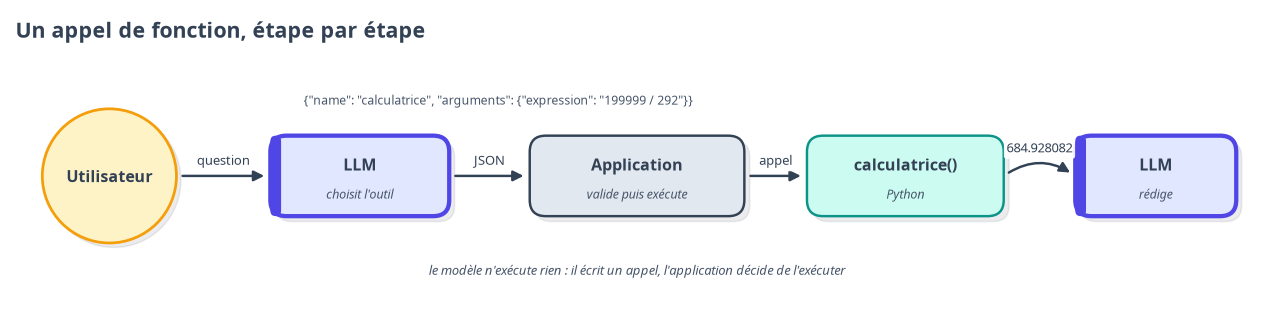

In [7]:
d = Diagram(14, 2.9, title="Un appel de fonction, étape par étape")
d.box("u", 1.1, 1.6, "Utilisateur", color=AMBER, kind="user", w=1.5)
d.box("m1", 3.9, 1.6, "LLM", sub="choisit l'outil", color=INDIGO, kind="model", w=2.0)
d.box("app", 7.0, 1.6, "Application", sub="valide puis exécute", color=SLATE, w=2.4)
d.box("f", 10.0, 1.6, "calculatrice()", sub="Python", color=TEAL, w=2.2)
d.box("m2", 12.8, 1.6, "LLM", sub="rédige", color=INDIGO, kind="model", w=1.8)
d.arrow("u", "m1", "question")
d.arrow("m1", "app", "JSON")
d.arrow("app", "f", "appel")
d.arrow("f", "m2", "684.928082", rad=-0.35)
d.note(5.45, 2.45, '{"name": "calculatrice", "arguments": {"expression": "199999 / 292"}}', fontsize=8, style="normal")
d.note(7.0, 0.55, "le modèle n'exécute rien : il écrit un appel, l'application décide de l'exécuter", fontsize=8.5)
d.show()

Donnons à Qwen les dix tâches de test du module, avec l'inventaire complet, et regardons sa
**première** décision : quel outil, avec quels arguments ? Puis le même essai en mode
« aucun outil » (`none`, simulé en ne déclarant pas d'outils).

In [8]:
schemas = [t.schema() for t in TOOLS.values()]
taches = c6.AGENT_TASKS
premiers = c6.generate_batch([[{"role": "user", "content": t["task"]}] for t in taches], max_new_tokens=80, tools=schemas)
sans_outils = c6.generate_batch([[{"role": "user", "content": t["task"]}] for t in taches], max_new_tokens=40)
lig = []
for t, out, no in zip(taches, premiers, sans_outils):
    _, calls = c6.parse_tool_calls(out)
    c = calls[0] if calls else None
    lig.append({"tâche": t["task"][:58], "outils attendus": ", ".join(t["tools"]) or "(aucun)",
                "1er appel (auto)": f"{c.get('name')}({json.dumps(c.get('arguments', {}), ensure_ascii=False)})"[:60] if c else "(texte)",
                "statut": c6.validate_call(c, TOOLS) if c else "-", "sans outils (none)": no[:50]})
pd.DataFrame(lig)

,tâche,outils attendus,1er appel (auto),statut,sans outils (none)
0,Combien coûtent 3 Fedoras Fruités chez Minou Chic ?,"recherche_corpus, calculatrice","calculatrice({""expression"": ""3 * 100""})",ok,"Je suis désolé, mais je ne peux pas fournir des in"
1,Combien font 199999 divisé par 292 ? Arrondis à deux décim,calculatrice,"calculatrice({""expression"": ""199999 / 292""})",ok,Pour calculer 199999 divisé par 292 et arrondir au
2,Quelle est la date d'aujourd'hui ?,date_du_jour,date_du_jour({}),ok,"Je suis désolé, mais je ne peux pas fournir une da"
3,Combien de jours reste-t-il entre aujourd'hui et le 31 déc,"date_du_jour, jours_entre","jours_entre({""date_debut"": ""2026-12-31"", ""date_fin"": ""2026-1",ok,Pour calculer combien de jours restent jusqu'au 31
4,Que signifie le code E-42 du thermostat Thermo-X200 ?,recherche_corpus,"recherche_corpus({""requete"": ""E-42 thermostat Thermo-X200""})",ok,"Le code ""E-42"" est un numéro unique utilisé pour i"
5,Quelle est la racine carrée de 1764 ?,calculatrice,"calculatrice({""expression"": ""sqrt(1764)""})",ok,La racine carrée de 1764 est 43.
6,Combien coûtent ensemble un Nœud Papillon Gala et un Imper,"recherche_corpus, calculatrice","calculatrice({""expression"": ""Nœud Papillon Gala + Imperméabl",ok,Pour calculer le coût total d'un Nœud Papillon Gal
7,"Combien vaut 17,5 % de 2 480 euros ?",calculatrice,"calculatrice({""expression"": ""17.5% de 2480""})",ok,"Pour calculer 17,5% de 2 480 euros, vous pouvez ut"
8,Bonjour ! Peux-tu te présenter en une phrase ?,(aucun),"calculatrice({""expression"": ""Bonjour ! Peux-tu te présenter",ok,"Bien sûr, je serai ravi de vous présenter en une p"
9,Quel temps fera-t-il demain à Lyon ?,(aucun),"recherche_corpus({""requete"": ""Lyon tomorrow weather""})",ok,"Je suis désolé, mais je ne peux pas fournir des in"


Les appels sont presque tous **syntaxiquement** valides (statut « ok » : outil existant,
paramètres attendus), et les cas simples partent vers le bon outil (racine carrée, date, code
d'erreur). Mais regardez les **valeurs** : un prix inventé (« 3 * 100 ») au lieu d'une recherche
préalable, une date de début erronée, du texte français glissé dans une expression
arithmétique, une salutation envoyée... à la calculatrice, et une question hors de portée des
outils (la météo) qui déclenche une recherche sans rapport. Le mode « auto » d'un petit modèle
sur-utilise les outils. Sans outils, le modèle répond de mémoire... et se trompe sur les calculs
et les faits fictifs. D'où le conseil du livre : **toujours inspecter les paramètres** de chaque
appel.

> **À retenir.** Dans l'appel de fonctions, le modèle **écrit** une demande structurée
> (nom + arguments JSON) et l'application l'**exécute**. Un JSON valide ne garantit pas des
> valeurs justes : il faut journaliser et vérifier chaque appel.